# McGreevy pitch location heat maps

For each pitch type Michael McGreevy threw at least 30 times to left-handed batters in 2026, I map his run value per 100 pitches by location. Red cells are good for McGreevy and blue cells are good for the batter. The maps are drawn from the catcher's view.

The data is every pitch McGreevy threw in 2026, pulled by `pulls/getMcgreevy.py`.

## Setup

- `BATTER_SIDE`: which batters to map, `"L"` for lefties or `"R"` for righties
- `MIN_PITCHES`: the fewest pitches a pitch type needs to get its own map
- `SMOOTHING`, `SHRINKAGE_PITCHES` and `MIN_PITCHES_IN_CELL` control how the maps handle cells with only a few pitches, explained below
- `CELLS_OUTSIDE_ZONE`: how many cells the grid extends past the strike zone on each side

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from scipy.ndimage import gaussian_filter

BATTER_SIDE = "L"
MIN_PITCHES = 30
SMOOTHING = 1.0
SHRINKAGE_PITCHES = 10
MIN_PITCHES_IN_CELL = 3
CELLS_OUTSIDE_ZONE = 2
HALF_PLATE = 17 / 12 / 2

## Load the pitches

I keep pitches to the chosen side that have a location, a run value and a pitch type.

Statcast's `delta_run_exp` is how much a pitch changed the batting team's expected runs. Positive is good for the batter, so I flip the sign: in `run_value`, positive is good for McGreevy.

In [2]:
pitches = pd.read_csv("../mcgreevy_2026.csv")
pitches = pitches.dropna(subset=["plate_x", "plate_z", "delta_run_exp", "pitch_type"])
pitches = pitches[pitches.stand == BATTER_SIDE]
pitches["run_value"] = -pitches.delta_run_exp

type_counts = pitches.pitch_type.value_counts()
pitch_types = [p for p in type_counts.index if type_counts[p] >= MIN_PITCHES]
pitch_names = pitches.groupby("pitch_type").pitch_name.first()

/tmp/ipykernel_230073/2213147460.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pitches["run_value"] = -pitches.delta_run_exp


## Build the grid

I split the strike zone into 3 × 3 cells, using the plate's width and McGreevy's average strike-zone top and bottom. Then I add `CELLS_OUTSIDE_ZONE` cells of the same size on every side, so the maps also show pitches out of the zone. `plate_x` is the pitch's side-to-side position and `plate_z` is its height, both in feet.

In [3]:
zone_top = pitches.sz_top.mean()
zone_bottom = pitches.sz_bot.mean()
cell_width = 2 * HALF_PLATE / 3
cell_height = (zone_top - zone_bottom) / 3

steps = np.arange(-CELLS_OUTSIDE_ZONE, 3 + CELLS_OUTSIDE_ZONE + 1)
x_edges = -HALF_PLATE + steps * cell_width
z_edges = zone_bottom + steps * cell_height
x_centers = (x_edges[:-1] + x_edges[1:]) / 2
z_centers = (z_edges[:-1] + z_edges[1:]) / 2

## Run value in each cell

For each pitch type, I count the pitches and add up their run value in every cell. Some cells only have a pitch or two, so one lucky or unlucky pitch could paint the whole cell. I handle that in three ways:

1. **Smoothing**: each cell is blended with its neighbors (`SMOOTHING` sets how much). Cells off the edge of the grid count as empty.
2. **Shrinkage**: each cell gets `SHRINKAGE_PITCHES` pretend pitches at the pitch type's overall average, so cells with few pitches stay close to that average.
3. **Hiding**: cells with fewer than `MIN_PITCHES_IN_CELL` pitches after smoothing are left blank.

All maps share one color scale centered on zero, so the same color means the same value on every map.

In [4]:
def run_value_grid(group):
    bins = [x_edges, z_edges]
    counts = np.histogram2d(group.plate_x, group.plate_z, bins=bins)[0].T
    totals = np.histogram2d(group.plate_x, group.plate_z, bins=bins, weights=group.run_value)[0].T

    counts = gaussian_filter(counts, SMOOTHING, mode="constant", truncate=3)
    totals = gaussian_filter(totals, SMOOTHING, mode="constant", truncate=3)

    average = group.run_value.mean()
    grid = 100 * (totals + SHRINKAGE_PITCHES * average) / (counts + SHRINKAGE_PITCHES)
    grid[counts < MIN_PITCHES_IN_CELL] = np.nan
    return grid


grids = {p: run_value_grid(pitches[pitches.pitch_type == p]) for p in pitch_types}

all_values = np.concatenate([g[~np.isnan(g)] for g in grids.values()])
color_limit = np.percentile(np.abs(all_values), 95)

## Draw the maps

One map per pitch type, three to a row. Each cell shows its run value per 100 pitches, with the strike zone outlined and home plate drawn underneath.

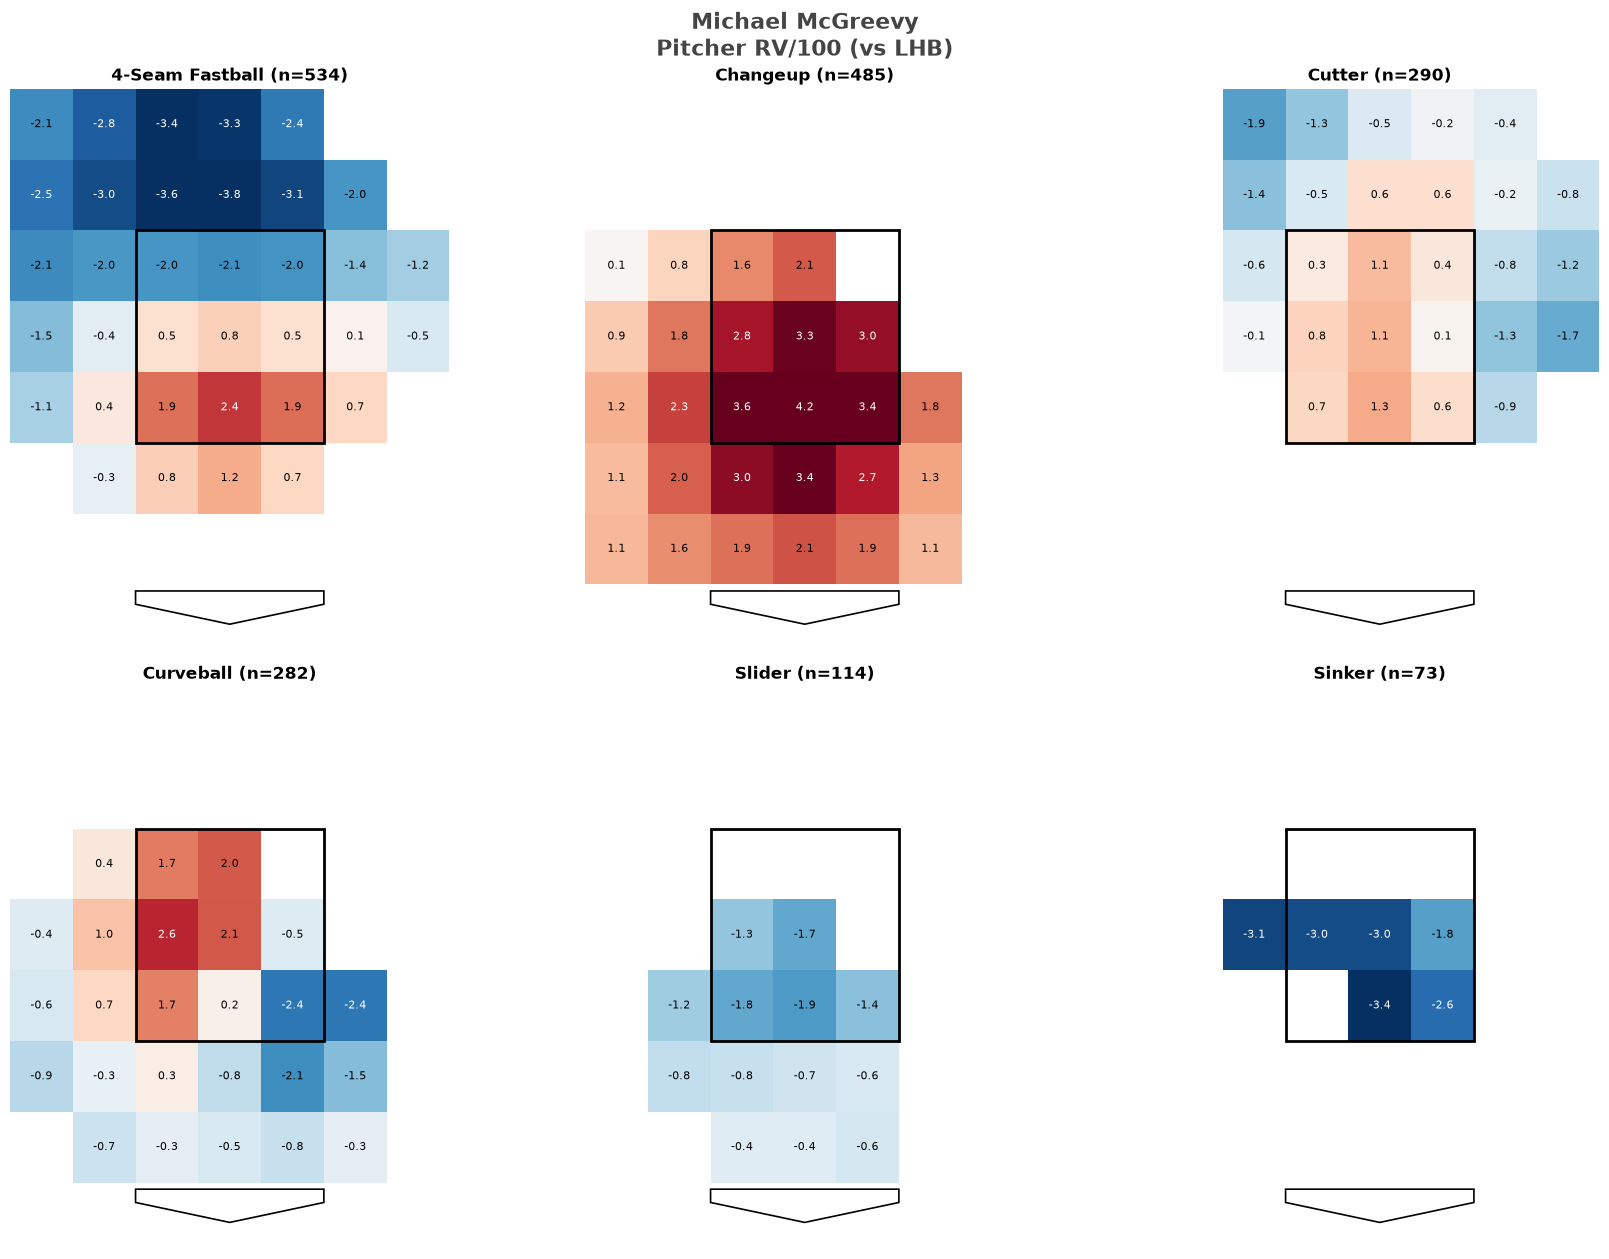

In [5]:
ncols = min(3, len(pitch_types))
nrows = int(np.ceil(len(pitch_types) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6.4 * nrows), squeeze=False)
plate_top = z_edges[0] - 0.05

for ax, pitch_type in zip(axes.flat, pitch_types):
    grid = grids[pitch_type]
    ax.set_facecolor("#f4f4f4")
    ax.pcolormesh(x_edges, z_edges, np.ma.masked_invalid(grid),
                  cmap="RdBu_r", vmin=-color_limit, vmax=color_limit, shading="flat")

    for i, z in enumerate(z_centers):
        for j, x in enumerate(x_centers):
            value = grid[i, j]
            if np.isnan(value):
                continue
            text_color = "white" if abs(value) > 0.65 * color_limit else "black"
            ax.text(x, z, f"{value:.1f}", ha="center", va="center", fontsize=8, color=text_color, zorder=4)

    ax.add_patch(Rectangle((-HALF_PLATE, zone_bottom), 2 * HALF_PLATE, zone_top - zone_bottom,
                           fill=False, edgecolor="black", linewidth=2, zorder=5))
    ax.add_patch(Polygon([(-HALF_PLATE, plate_top), (HALF_PLATE, plate_top),
                          (HALF_PLATE, plate_top - 0.1), (0, plate_top - 0.25),
                          (-HALF_PLATE, plate_top - 0.1)],
                         facecolor="white", edgecolor="black", linewidth=1.2, zorder=5))

    ax.set_xlim(x_edges[0], x_edges[-1])
    ax.set_ylim(z_edges[0] - 0.5, z_edges[-1])
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{pitch_names[pitch_type]} (n={type_counts[pitch_type]})", fontsize=12, fontweight="bold")

for ax in list(axes.flat)[len(pitch_types):]:
    ax.axis("off")

fig.suptitle(f"Michael McGreevy\nPitcher RV/100 (vs {BATTER_SIDE}HB)", fontsize=16, fontweight="bold", color="#444444")
fig.tight_layout()
plt.show()